In [41]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


In [42]:

raw_files = [f"annual_reports/{year}.csv" for year in range(2015,2020)] 
dblist = [pd.read_csv(file) for file in raw_files]
db15,db16,db17,db18,db19 = dblist
years = np.arange(2015,2020)

-----

1. What does the distribution of the variable Score loook like? (Histograms?)

Something that quickly becomes apparent is the mismatch of labeling between the datasets. So rather than evoking the database columns directly, I'm using pandas's `db.like` function.

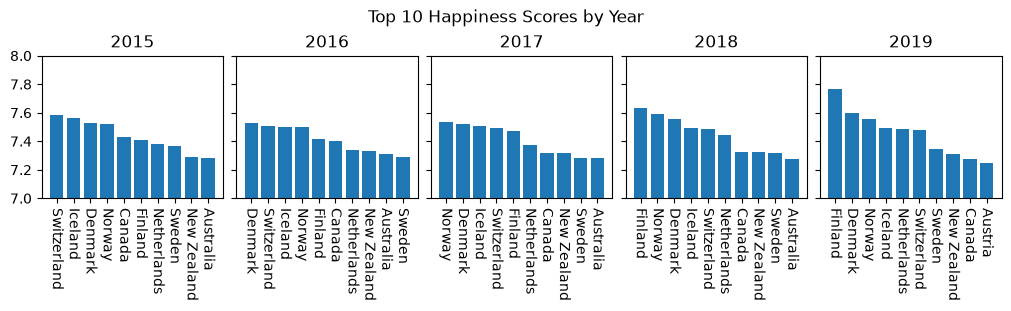

In [43]:

fig1, axes1 = plt.subplots(1,5, figsize = (10,3), constrained_layout = True)
axes1[0].set_ylim(7,8)
axes1[0].set_yticks(np.arange(7,8.2,.2),[f'{a:.1f}' for a in np.arange(7,8.2,.2)])
for year,db, ax in zip(years,dblist,axes1):
    ax.bar(db.filter(like = "Country").squeeze()[:10],db.filter(like = "Score").squeeze()[:10])
    ax.tick_params(axis = 'x', rotation = -90)
    ax.set_title(f'{year}')

    if ax != axes1[0]:
        ax.sharey(axes1[0])
        ax.tick_params(labelleft = False)


fig1.suptitle('Top 10 Happiness Scores by Year');


2. Is there any visible relationship between GDP and Healthy? Scatter plot, and label notable countries.

Yes, it seems almost linear.

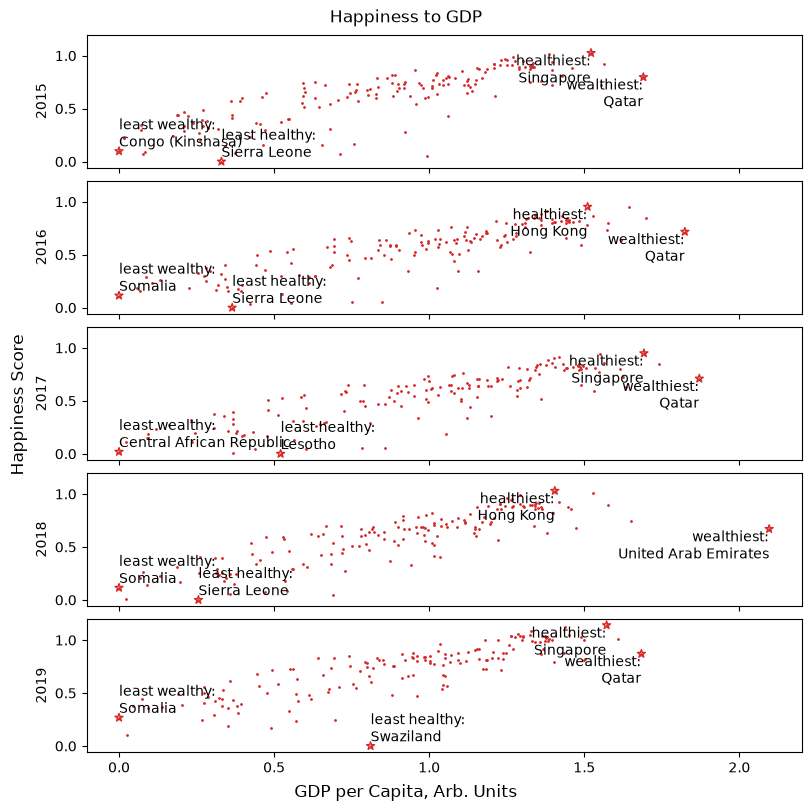

In [55]:
fig2, axes2 = plt.subplots(5,figsize = (8,8), constrained_layout = True)
for i,(db,ax,year) in enumerate(zip(dblist,axes2,years)):
    X = db.filter(like = 'GDP').squeeze()
    Y = db.filter(like = 'Health').squeeze()
    ax.scatter(X,Y, s=1,c='tab:red')

    happiness = db.filter(like = 'Score').squeeze()
    countries = db.filter(like = "Country").squeeze()
    wealthDex = np.argmax(X)
    poorDex = np.argmin(X)
    healthDex = np.argmax(Y)
    sickDex = np.argmin(Y)
    happyDex = np.argmax(happiness)
    sadDex = np.argmin(happiness)

    notableDexes = [
        wealthDex, poorDex, healthDex, sickDex
    ]
    notableCountries = [countries[dex] for dex in notableDexes]
    notableTitles = [
        'wealthiest', 'least wealthy', 'healthiest', 'least healthy']
    notableLabels = [f'{title}:\n{country}' for title, country in zip (notableTitles,notableCountries)]
    
    ax.scatter(X[notableDexes],Y[notableDexes], marker = '*', facecolor = "none", edgecolor = 'tab:red')

    for dex,label in zip(notableDexes,notableLabels):
        x,y = X[dex],Y[dex]
        top = (y > (Y.max()-Y.min())/2)
        right =(x> (X.max()-X.min())/2)

        ax.annotate(label,(x,y), ha = ('right' if right else 'left'), va = ('top' if top else 'bottom'))
    if i<4:
        ax.sharex(axes2[4])
        ax.sharey(axes2[4])
    if i<4:
        ax.tick_params(labelbottom = False)
    ax.set_ylabel(f'{year}')
fig2.suptitle("Happiness to GDP");
fig2.supylabel('Happiness Score');
fig2.supxlabel('GDP per Capita, Arb. Units');


In [45]:
Y

0      0.986
1      0.996
2      1.028
3      1.026
4      0.999
       ...  
151    0.614
152    0.499
153    0.361
154    0.105
155    0.295
Name: Healthy life expectancy, Length: 156, dtype: float64

In [47]:
Y.max()

np.float64(1.141)